# 14. GRU bayesiana — notebook de Ana reconstruido y corregido

Esta versión conserva la idea central del notebook original: PyTorch + `bayesian-torch`, GRU/LSTM/DNN opcionales, salida directa para horizontes 1, 7 y 30, target en log-diferencias respecto al último precio conocido y muestreo Monte Carlo.

## Correcciones realizadas
- Usa `data/processed/dataset_consolidado.parquet`.
- Compatible con **MPS (Mac)**, CUDA y CPU.
- Test común: **2025-08-01 a 2026-07-31**.
- La validación queda separada del entrenamiento.
- **El test no se usa para escoger hiperparámetros.**
- Cada secuencia conserva sus **fechas objetivo exactas**. Esto corrige el aparente rezago del notebook original, que graficaba todos los horizontes contra `test_dates[:len(...)]`.
- Se añaden variables de régimen del precio construidas solo con presente/pasado.
- Guarda resultados en las rutas comunes del proyecto.

El target es:

\[
y_{t,h}=\log(1+P_{t+h})-\log(1+P_t)
\]

Esto mantiene el pronóstico anclado al nivel observado en el origen.

In [1]:
from pathlib import Path
import copy, itertools, os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, median_absolute_error, max_error

warnings.filterwarnings("ignore")
try:
    from bayesian_torch.models.dnn_to_bnn import dnn_to_bnn, get_kl_loss
except ImportError as e:
    raise ImportError("Instala bayesian-torch con: pip install bayesian-torch") from e

SEED=42
def seed_all(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
seed_all()

device = torch.device("mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu"))
print("Dispositivo:", device)

Dispositivo: mps


In [2]:
def repo_root(start=None):
    p=Path(start or Path.cwd()).resolve()
    for q in [p,*p.parents]:
        if (q/".git").exists(): return q
    raise FileNotFoundError("No se encontró la raíz del repo (.git).")

ROOT=repo_root()
DATA=ROOT/"data"/"processed"/"dataset_consolidado.parquet"
METRICS=ROOT/"data"/"processed"/"tabla_metricas.parquet"
MODEL_DIR=ROOT/"models"/"gru_bayesiana_ana_corregida"
REPORT_DIR=ROOT/"reports"/"gru_bayesiana_ana_corregida"
MODEL_DIR.mkdir(parents=True,exist_ok=True); REPORT_DIR.mkdir(parents=True,exist_ok=True)

df=pd.read_parquet(DATA).copy()
if not isinstance(df.index,pd.DatetimeIndex):
    fc=next((c for c in ["fecha","Fecha","date","Date"] if c in df.columns),None)
    if fc is None: raise ValueError("No se encontró fecha.")
    df[fc]=pd.to_datetime(df[fc]); df=df.set_index(fc)
df.index=pd.to_datetime(df.index); df=df.sort_index()
df=df[~df.index.duplicated(keep="last")].select_dtypes(include=[np.number])

TARGET="precio_bolsa"
if TARGET not in df: raise KeyError(f"Falta {TARGET}")
print("ROOT:",ROOT)
print("Rango:",df.index.min().date(),"→",df.index.max().date(),"| filas:",len(df))
print(list(df.columns))

ROOT: /Users/maguverm/Documents/tesis-bolsa
Rango: 2013-01-01 → 2026-07-31 | filas: 4960
['precio_bolsa', 'aportes_energia_gwh', 'vertimientos_energia_gwh', 'gen_cogenerador', 'gen_eolica', 'gen_hidraulica', 'gen_solar', 'gen_termica', 'disp_cogenerador', 'disp_hidraulica', 'disp_solar', 'disp_termica', 'precio_escasez', 'ONI', 'TRM']


In [3]:
# Features de calendario y régimen. Todas usan solo información disponible hasta t.
p=df[TARGET].astype(float)
df["dow_sin"]=np.sin(2*np.pi*df.index.dayofweek/7)
df["dow_cos"]=np.cos(2*np.pi*df.index.dayofweek/7)
df["month_sin"]=np.sin(2*np.pi*(df.index.month-1)/12)
df["month_cos"]=np.cos(2*np.pi*(df.index.month-1)/12)
df["fin_semana"]=(df.index.dayofweek>=5).astype(float)

df["precio_ma7"]=p.rolling(7).mean()
df["precio_ma30"]=p.rolling(30).mean()
df["precio_std7"]=p.rolling(7).std()
df["precio_std30"]=p.rolling(30).std()
df["precio_min30"]=p.rolling(30).min()
df["precio_max30"]=p.rolling(30).max()
df["precio_rel_ma7"]=p/df["precio_ma7"]
df["precio_rel_ma30"]=p/df["precio_ma30"]
df["precio_z30"]=(p-df["precio_ma30"])/df["precio_std30"].replace(0,np.nan)
df["precio_cambio1"]=p.pct_change(1)
df["precio_cambio7"]=p.pct_change(7)

aliases={
 "aportes":["aportes_energia_gwh","aportes_energia","aportes"],
 "gen_termica":["gen_termica","generacion_termica"],
 "demanda":["demanda","demanda_energia"],
 "vol_util":["vol_util","volumen_util","energia_embalsada"]
}
for _,opts in aliases.items():
    col=next((x for x in opts if x in df.columns),None)
    if col:
        df[f"{col}_ma7"]=df[col].rolling(7).mean()
        df[f"{col}_ma30"]=df[col].rolling(30).mean()
        df[f"{col}_cambio7"]=df[col].pct_change(7)

df=df.replace([np.inf,-np.inf],np.nan).dropna().copy()
FEATURES=list(df.columns)
print("Features:",len(FEATURES))
print(FEATURES)

Features: 37
['precio_bolsa', 'aportes_energia_gwh', 'vertimientos_energia_gwh', 'gen_cogenerador', 'gen_eolica', 'gen_hidraulica', 'gen_solar', 'gen_termica', 'disp_cogenerador', 'disp_hidraulica', 'disp_solar', 'disp_termica', 'precio_escasez', 'ONI', 'TRM', 'dow_sin', 'dow_cos', 'month_sin', 'month_cos', 'fin_semana', 'precio_ma7', 'precio_ma30', 'precio_std7', 'precio_std30', 'precio_min30', 'precio_max30', 'precio_rel_ma7', 'precio_rel_ma30', 'precio_z30', 'precio_cambio1', 'precio_cambio7', 'aportes_energia_gwh_ma7', 'aportes_energia_gwh_ma30', 'aportes_energia_gwh_cambio7', 'gen_termica_ma7', 'gen_termica_ma30', 'gen_termica_cambio7']


In [4]:
HORIZONTES=[1,7,30]
LOOKBACKS=[60]
MODELOS=["GRU"]
NEURONAS=[32,64,128]
LRS=[1e-3,5e-4]
DROPOUTS=[0.2,0.3]
EPOCHS_MAX=300
BATCH=32
PATIENCE=35
N_MC_SEARCH=20
N_MC_FINAL=100

TEST_START=pd.Timestamp("2025-08-01")
TEST_END=pd.Timestamp("2026-07-31")
VAL_END=TEST_START-pd.Timedelta(days=1)
VAL_START=TEST_START-pd.Timedelta(days=365)

train=df[df.index<VAL_START].copy()
val=df[(df.index>=VAL_START)&(df.index<=VAL_END)].copy()
test=df[(df.index>=TEST_START)&(df.index<=TEST_END)].copy()
print("Train:",train.index.min().date(),"→",train.index.max().date(),len(train))
print("Val:  ",val.index.min().date(),"→",val.index.max().date(),len(val))
print("Test: ",test.index.min().date(),"→",test.index.max().date(),len(test))

Train: 2013-01-30 → 2024-07-31 4201
Val:   2024-08-01 → 2025-07-31 365
Test:  2025-08-01 → 2026-07-31 365


In [5]:
# Escalado ajustado SOLO con train de selección
scaler_sel=StandardScaler().fit(train[FEATURES])
s_train=pd.DataFrame(scaler_sel.transform(train[FEATURES]),index=train.index,columns=FEATURES)

def secuencias(scaled,raw,lag,horizontes,origin_start=None,origin_end=None):
    assert scaled.index.equals(raw.index)
    idx=raw.index
    logp=np.log1p(raw[TARGET].astype(float).values)
    vals=scaled[FEATURES].values
    X,Y,A,O,D=[],[],[],[],[]
    for i in range(lag,len(raw)-max(horizontes)+1):
        origen=idx[i-1]
        if origin_start is not None and origen<pd.Timestamp(origin_start): continue
        if origin_end is not None and origen>pd.Timestamp(origin_end): continue
        a=logp[i-1]
        X.append(vals[i-lag:i])
        Y.append([logp[i+h-1]-a for h in horizontes])
        A.append(a); O.append(origen)
        D.append([idx[i+h-1] for h in horizontes])
    return {"X":np.asarray(X,np.float32),"Y":np.asarray(Y,np.float32),
            "A":np.asarray(A,float),"O":pd.DatetimeIndex(O),
            "D":np.asarray(D,dtype="datetime64[ns]")}

def check_dates(b,n=3):
    for j in range(min(n,len(b["X"]))):
        o=pd.Timestamp(b["O"][j]); ds=[pd.Timestamp(x) for x in b["D"][j]]
        delta=[(x-o).days for x in ds]
        print(o.date(),"→",[x.date() for x in ds],"Δ",delta)
        assert delta==HORIZONTES

train_b={}; val_b={}; diff_sel={}
for lag in LOOKBACKS:
    bt=secuencias(s_train,train[FEATURES],lag,HORIZONTES)
    rawctx=pd.concat([train.tail(lag),val])
    sctx=pd.DataFrame(scaler_sel.transform(rawctx[FEATURES]),index=rawctx.index,columns=FEATURES)
    bv=secuencias(sctx,rawctx[FEATURES],lag,HORIZONTES,
                 VAL_START-pd.Timedelta(days=1),VAL_END-pd.Timedelta(days=max(HORIZONTES)))
    ds=StandardScaler().fit(bt["Y"])
    bt["Ys"]=ds.transform(bt["Y"]).astype(np.float32)
    bv["Ys"]=ds.transform(bv["Y"]).astype(np.float32)
    train_b[lag]=bt; val_b[lag]=bv; diff_sel[lag]=ds
    print("\nLag",lag,"train",len(bt["X"]),"val",len(bv["X"]))
    check_dates(bv,2)


Lag 60 train 4112 val 336
2024-07-31 → [datetime.date(2024, 8, 1), datetime.date(2024, 8, 7), datetime.date(2024, 8, 30)] Δ [1, 7, 30]
2024-08-01 → [datetime.date(2024, 8, 2), datetime.date(2024, 8, 8), datetime.date(2024, 8, 31)] Δ [1, 7, 30]


In [6]:
PRIOR={"prior_mu":0.0,"prior_sigma":1.0,"posterior_mu_init":0.0,
       "posterior_rho_init":-3.0,"type":"Reparameterization",
       "moped_enable":False,"moped_delta":0.5}

def bayes_head(nin,nout):
    h=nn.Sequential(nn.Linear(nin,nout)); dnn_to_bnn(h,PRIOR); return h

class SeqNet(nn.Module):
    def __init__(self,tipo,nf,n,drop):
        super().__init__()
        R=nn.LSTM if tipo=="LSTM" else nn.GRU
        n2=max(n//2,8)
        self.r1=R(nf,n,batch_first=True); self.d1=nn.Dropout(drop)
        self.r2=R(n,n2,batch_first=True); self.d2=nn.Dropout(drop)
        self.head=bayes_head(n2,len(HORIZONTES))
    def forward(self,x):
        x,_=self.r1(x); x=self.d1(x); x,_=self.r2(x)
        return self.head(self.d2(x[:,-1,:]))

class DNN(nn.Module):
    def __init__(self,nf,lag,n,drop):
        super().__init__(); n2=max(n//2,8)
        self.body=nn.Sequential(nn.Linear(nf*lag,n),nn.Tanh(),nn.Dropout(drop),
                                nn.Linear(n,n2),nn.Tanh(),nn.Dropout(drop))
        dnn_to_bnn(self.body,PRIOR); self.head=bayes_head(n2,len(HORIZONTES))
    def forward(self,x): return self.head(self.body(x.reshape(x.shape[0],-1)))

def make_model(tipo,lag,nf,n,drop):
    return (DNN(nf,lag,n,drop) if tipo=="DNN" else SeqNet(tipo,nf,n,drop)).to(device)

In [7]:
def fit(model,X,y,Xv,yv,epochs,lr,patience=PATIENCE):
    opt=torch.optim.Adam(model.parameters(),lr=lr); mse=nn.MSELoss()
    X=torch.tensor(X,dtype=torch.float32); y=torch.tensor(y,dtype=torch.float32)
    Xv=torch.tensor(Xv,dtype=torch.float32).to(device); yv=torch.tensor(yv,dtype=torch.float32).to(device)
    best=np.inf; state=None; best_epoch=0; wait=0; hist={"loss":[],"val_loss":[]}
    for ep in range(1,epochs+1):
        model.train(); ls=[]
        for i in range(0,len(X),BATCH):
            xb=X[i:i+BATCH].to(device); yb=y[i:i+BATCH].to(device)
            opt.zero_grad(); pred=model(xb); emse=mse(pred,yb)
            loss=emse+get_kl_loss(model)/max(len(xb),1)
            loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(),1.0); opt.step()
            ls.append(emse.item())
        model.eval()
        with torch.no_grad(): vl=mse(model(Xv),yv).item()
        hist["loss"].append(float(np.mean(ls))); hist["val_loss"].append(vl)
        if vl<best-1e-7:
            best=vl; state=copy.deepcopy(model.state_dict()); best_epoch=ep; wait=0
        else:
            wait+=1
            if wait>=patience: break
    model.load_state_dict(state)
    return model,hist,best,best_epoch

def mc(model,X,n=100):
    model.eval(); Xt=torch.tensor(X,dtype=torch.float32)
    z=np.empty((n,len(X),len(HORIZONTES)),np.float32)
    with torch.no_grad():
        for m in range(n):
            parts=[]
            for i in range(0,len(Xt),1024):
                parts.append(model(Xt[i:i+1024].to(device)).cpu().numpy())
            z[m]=np.concatenate(parts)
    return z

def samples_price(z,A,ds,hi):
    raw=z*ds.scale_[hi]+ds.mean_[hi]
    return np.expm1(A[None,:]+raw)

def true_price(Y,A,hi): return np.expm1(A+Y[:,hi])

def metrics(y,p):
    eps=1e-8
    return {"MAE":mean_absolute_error(y,p),
            "RMSE":np.sqrt(mean_squared_error(y,p)),
            "MAPE (%)":np.mean(np.abs((y-p)/(np.abs(y)+eps)))*100,
            "sMAPE (%)":np.mean(2*np.abs(y-p)/(np.abs(y)+np.abs(p)+eps))*100,
            "R²":r2_score(y,p),"MedAE":median_absolute_error(y,p),
            "MaxError":max_error(y,p),"Sesgo":np.mean(p-y)}

def eval_bundle(model,b,ds,nmc):
    z=mc(model,b["X"],nmc); rows=[]
    for hi,h in enumerate(HORIZONTES):
        y=true_price(b["Y"],b["A"],hi)
        p=samples_price(z[:,:,hi],b["A"],ds,hi).mean(0)
        rows.append({"Horizonte":h,**metrics(y,p)})
    return pd.DataFrame(rows)

In [8]:
# Búsqueda: el mejor modelo se escoge EXCLUSIVAMENTE por validación.
rows=[]; best_cfg=None; best_score=np.inf
for lag,tipo,n,lr,drop in itertools.product(LOOKBACKS,MODELOS,NEURONAS,LRS,DROPOUTS):
    seed_all()
    bt,bv=train_b[lag],val_b[lag]
    model=make_model(tipo,lag,bt["X"].shape[-1],n,drop)
    model,hist,vl,bep=fit(model,bt["X"],bt["Ys"],bv["X"],bv["Ys"],EPOCHS_MAX,lr)
    vm=eval_bundle(model,bv,diff_sel[lag],N_MC_SEARCH)
    score=vm["RMSE"].mean()
    row={"Modelo":tipo,"LookBack":lag,"Neuronas":n,"lr":lr,"dropout":drop,
         "best_epoch":bep,"val_loss_scaled":vl,"score_val_RMSE_medio":score}
    for _,r in vm.iterrows():
        h=int(r["Horizonte"]); row[f"RMSE_val_h{h}"]=r["RMSE"]; row[f"MAPE_val_h{h}"]=r["MAPE (%)"]
    rows.append(row)
    print(f"{tipo} lag={lag} n={n} lr={lr} drop={drop} -> RMSE val={score:.2f} epoch={bep}")
    if score<best_score: best_score=score; best_cfg=row.copy()

search=pd.DataFrame(rows).sort_values("score_val_RMSE_medio")
display(search)
print("\nMEJOR CONFIGURACIÓN:",best_cfg)
search.to_csv(REPORT_DIR/"busqueda_hiperparametros.csv",index=False)

GRU lag=60 n=32 lr=0.001 drop=0.2 -> RMSE val=316.35 epoch=6
GRU lag=60 n=32 lr=0.001 drop=0.3 -> RMSE val=314.66 epoch=6
GRU lag=60 n=32 lr=0.0005 drop=0.2 -> RMSE val=312.78 epoch=6
GRU lag=60 n=32 lr=0.0005 drop=0.3 -> RMSE val=312.27 epoch=6
GRU lag=60 n=64 lr=0.001 drop=0.2 -> RMSE val=333.51 epoch=9
GRU lag=60 n=64 lr=0.001 drop=0.3 -> RMSE val=329.74 epoch=19
GRU lag=60 n=64 lr=0.0005 drop=0.2 -> RMSE val=322.78 epoch=7
GRU lag=60 n=64 lr=0.0005 drop=0.3 -> RMSE val=319.66 epoch=6
GRU lag=60 n=128 lr=0.001 drop=0.2 -> RMSE val=316.75 epoch=4
GRU lag=60 n=128 lr=0.001 drop=0.3 -> RMSE val=318.66 epoch=4
GRU lag=60 n=128 lr=0.0005 drop=0.2 -> RMSE val=323.62 epoch=20
GRU lag=60 n=128 lr=0.0005 drop=0.3 -> RMSE val=323.23 epoch=14


,Modelo,LookBack,Neuronas,lr,dropout,best_epoch,val_loss_scaled,score_val_RMSE_medio,RMSE_val_h1,MAPE_val_h1,RMSE_val_h7,MAPE_val_h7,RMSE_val_h30,MAPE_val_h30
3,GRU,60,32,0.0005,0.3,6,1.886331,312.269107,186.881829,14.287956,295.037396,30.415495,454.888097,73.388404
2,GRU,60,32,0.0005,0.2,6,1.894712,312.776459,186.816325,14.247889,295.891402,30.651714,455.621649,74.239914
1,GRU,60,32,0.0010,0.3,6,1.859915,314.658661,186.321813,14.019853,299.436239,30.193882,458.217932,68.307801
0,GRU,60,32,0.0010,0.2,6,1.878627,316.352061,186.405193,13.985861,301.151866,30.305335,461.499125,68.831851
8,GRU,60,128,0.0010,0.2,4,1.829212,316.745075,187.441215,14.359274,313.802568,32.160317,448.991443,55.665232
9,GRU,60,128,0.0010,0.3,4,1.790765,318.655093,186.934415,14.196073,311.372673,30.825296,457.658191,52.937319
7,GRU,60,64,0.0005,0.3,6,1.823163,319.658931,184.507649,13.849810,310.443515,30.392685,464.025629,55.811595
6,GRU,60,64,0.0005,0.2,7,1.823273,322.781885,183.898440,13.771167,316.307248,29.517327,468.139966,57.805293
11,GRU,60,128,0.0005,0.3,14,1.829475,323.230733,186.135514,13.921825,314.239849,29.738531,469.316835,43.819610
10,GRU,60,128,0.0005,0.2,20,1.780683,323.622150,185.401250,13.334385,344.246685,29.466482,441.218516,47.788998



MEJOR CONFIGURACIÓN: {'Modelo': 'GRU', 'LookBack': 60, 'Neuronas': 32, 'lr': 0.0005, 'dropout': 0.3, 'best_epoch': 6, 'val_loss_scaled': 1.8863307237625122, 'score_val_RMSE_medio': np.float64(312.26910724335335), 'RMSE_val_h1': np.float64(186.8818292394377), 'MAPE_val_h1': np.float64(14.287956218146322), 'RMSE_val_h7': np.float64(295.03739576553016), 'MAPE_val_h7': np.float64(30.415494793855835), 'RMSE_val_h30': np.float64(454.8880967250921), 'MAPE_val_h30': np.float64(73.3884044138302)}


In [9]:
# Reentrenamiento final con todo lo anterior al test.
pre=df[df.index<TEST_START].copy()
scaler=StandardScaler().fit(pre[FEATURES])
spre=pd.DataFrame(scaler.transform(pre[FEATURES]),index=pre.index,columns=FEATURES)
lag=int(best_cfg["LookBack"])
bp=secuencias(spre,pre[FEATURES],lag,HORIZONTES)
ds=StandardScaler().fit(bp["Y"]); bp["Ys"]=ds.transform(bp["Y"]).astype(np.float32)

seed_all()
model=make_model(best_cfg["Modelo"],lag,bp["X"].shape[-1],int(best_cfg["Neuronas"]),float(best_cfg["dropout"]))

def fit_fixed(model,X,y,epochs,lr):
    opt=torch.optim.Adam(model.parameters(),lr=lr); mse=nn.MSELoss()
    X=torch.tensor(X,dtype=torch.float32); y=torch.tensor(y,dtype=torch.float32)
    hist=[]
    for ep in range(int(epochs)):
        model.train(); ls=[]
        for i in range(0,len(X),BATCH):
            xb=X[i:i+BATCH].to(device); yb=y[i:i+BATCH].to(device)
            opt.zero_grad(); pred=model(xb); emse=mse(pred,yb)
            loss=emse+get_kl_loss(model)/max(len(xb),1)
            loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(),1.0); opt.step()
            ls.append(emse.item())
        hist.append(float(np.mean(ls)))
    return model,hist

model,final_hist=fit_fixed(model,bp["X"],bp["Ys"],best_cfg["best_epoch"],best_cfg["lr"])
print("Modelo final entrenado",best_cfg["best_epoch"],"épocas.")

Modelo final entrenado 6 épocas.


In [10]:
# Test: contexto histórico + fechas objetivo exactas.
rawctx=pd.concat([pre.tail(lag),test])
sctx=pd.DataFrame(scaler.transform(rawctx[FEATURES]),index=rawctx.index,columns=FEATURES)
bt=secuencias(sctx,rawctx[FEATURES],lag,HORIZONTES,
             TEST_START-pd.Timedelta(days=1),TEST_END-pd.Timedelta(days=max(HORIZONTES)))
bt["Ys"]=ds.transform(bt["Y"]).astype(np.float32)

print("CHEQUEO DE FECHAS:")
check_dates(bt,5)
for hi,h in enumerate(HORIZONTES):
    dates=pd.to_datetime(bt["D"][:,hi])
    assert dates.min()>=TEST_START and dates.max()<=TEST_END
    print(f"h={h}: {dates.min().date()} -> {dates.max().date()} | n={len(dates)}")

CHEQUEO DE FECHAS:
2025-07-31 → [datetime.date(2025, 8, 1), datetime.date(2025, 8, 7), datetime.date(2025, 8, 30)] Δ [1, 7, 30]
2025-08-01 → [datetime.date(2025, 8, 2), datetime.date(2025, 8, 8), datetime.date(2025, 8, 31)] Δ [1, 7, 30]
2025-08-02 → [datetime.date(2025, 8, 3), datetime.date(2025, 8, 9), datetime.date(2025, 9, 1)] Δ [1, 7, 30]
2025-08-03 → [datetime.date(2025, 8, 4), datetime.date(2025, 8, 10), datetime.date(2025, 9, 2)] Δ [1, 7, 30]
2025-08-04 → [datetime.date(2025, 8, 5), datetime.date(2025, 8, 11), datetime.date(2025, 9, 3)] Δ [1, 7, 30]
h=1: 2025-08-01 -> 2026-07-02 | n=336
h=7: 2025-08-07 -> 2026-07-08 | n=336
h=30: 2025-08-30 -> 2026-07-31 | n=336



HORIZONTE 1 {'MAE': 39.65257636084454, 'RMSE': np.float64(58.188500283364036), 'MAPE (%)': np.float64(13.937898212100075), 'sMAPE (%)': np.float64(14.119461630470326), 'R²': 0.8777598095810261, 'MedAE': 26.215419243574303, 'MaxError': 239.67693548953946, 'Sesgo': np.float64(-14.32042973236567)}


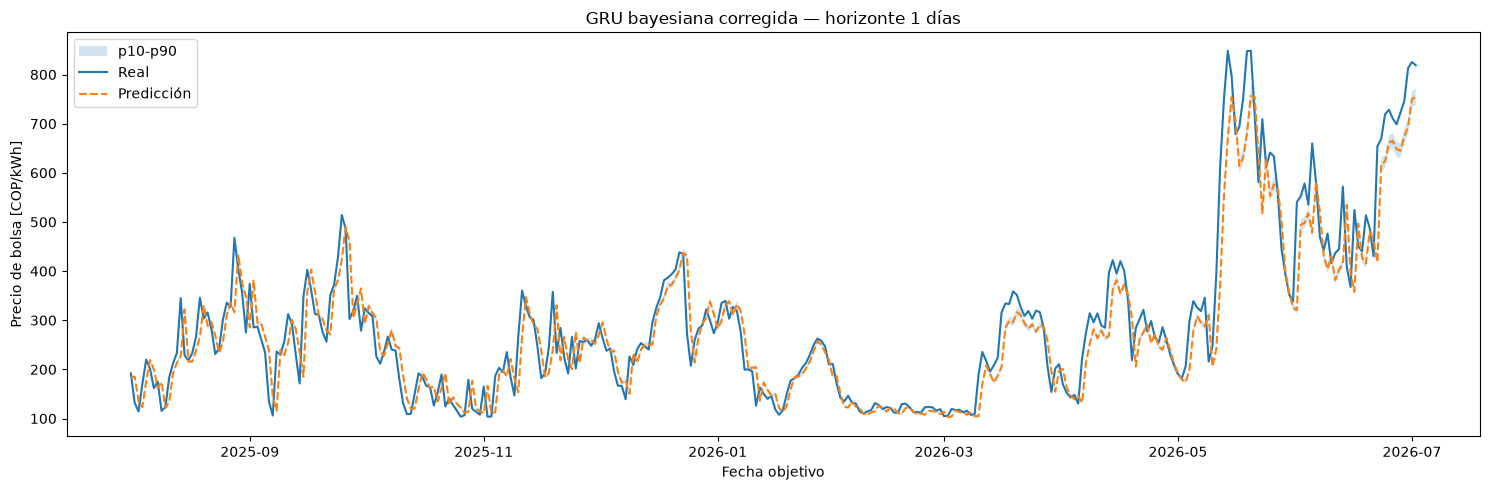


HORIZONTE 7 {'MAE': 86.60633857302503, 'RMSE': np.float64(121.39707653901787), 'MAPE (%)': np.float64(30.806481655081306), 'sMAPE (%)': np.float64(29.19612659539692), 'R²': 0.5280612048707334, 'MedAE': 61.271889767325746, 'MaxError': 571.0701508741115, 'Sesgo': np.float64(-19.841902461759766)}


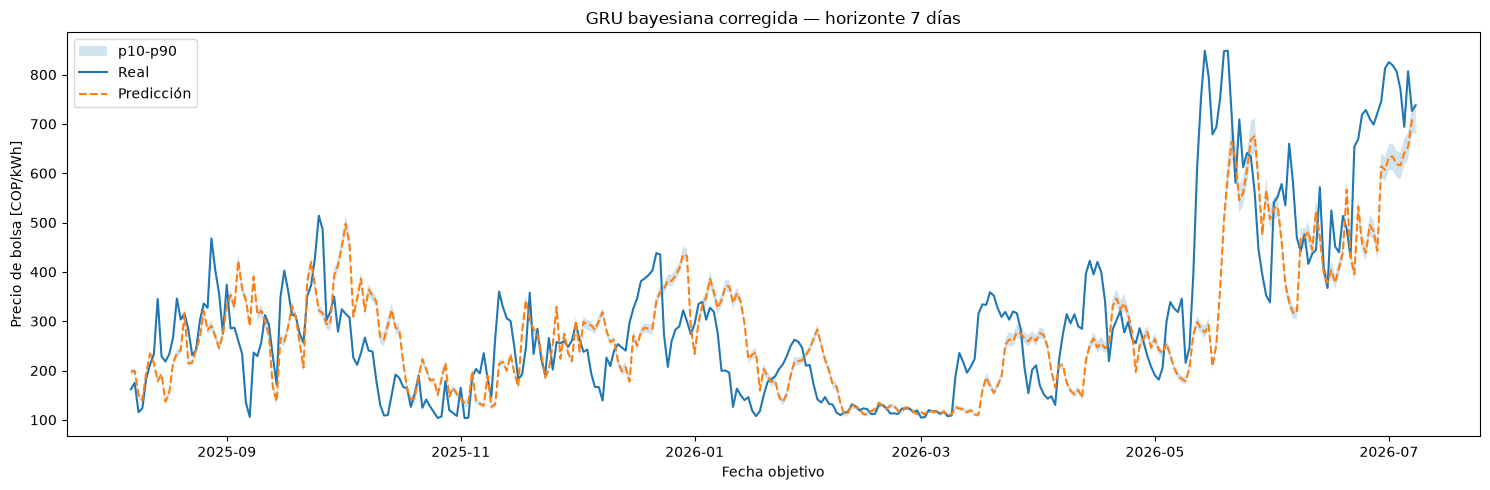


HORIZONTE 30 {'MAE': 158.23469234921785, 'RMSE': np.float64(204.1502011160376), 'MAPE (%)': np.float64(57.45626191900064), 'sMAPE (%)': np.float64(49.16173406860649), 'R²': 0.11921437071330343, 'MedAE': 124.36311000131018, 'MaxError': 643.6539078937318, 'Sesgo': np.float64(-50.233018229800194)}


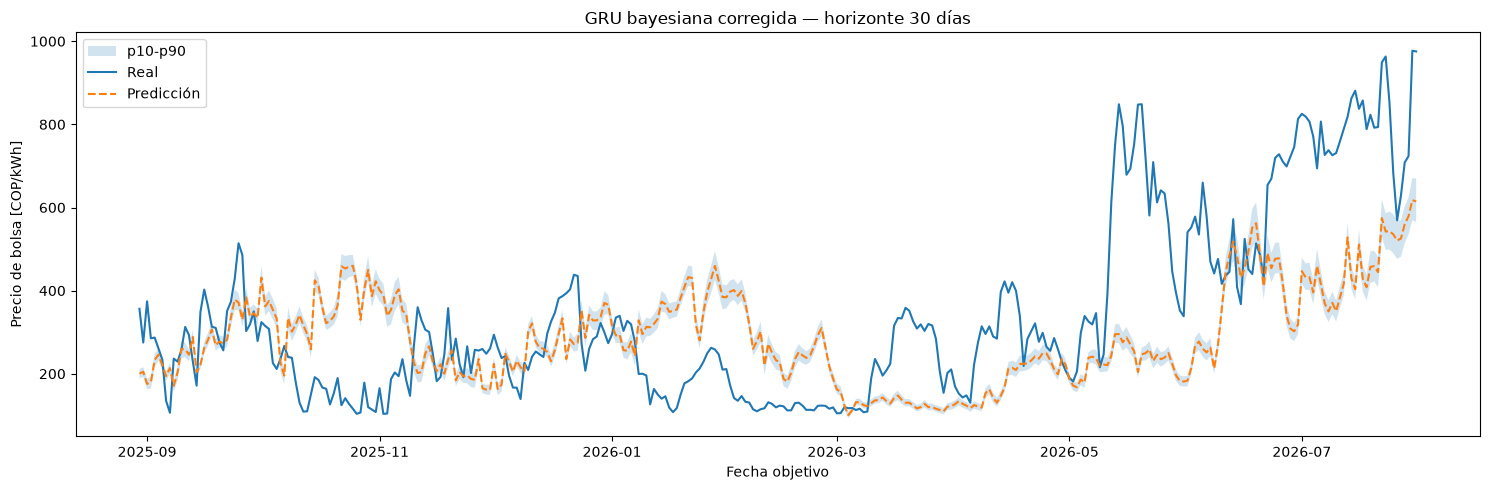

,Modelo,Horizonte,MAE,RMSE,MAPE (%),sMAPE (%),R²,MedAE,MaxError,Sesgo
0,GRU_Bayes_Ana_Corregida,1,39.652576,58.188500,13.937898,14.119462,0.877760,26.215419,239.676935,-14.320430
1,GRU_Bayes_Ana_Corregida,7,86.606339,121.397077,30.806482,29.196127,0.528061,61.271890,571.070151,-19.841902
2,GRU_Bayes_Ana_Corregida,30,158.234692,204.150201,57.456262,49.161734,0.119214,124.363110,643.653908,-50.233018


In [11]:
# Evaluación final y gráficos YA ALINEADOS.
Z=mc(model,bt["X"],N_MC_FINAL)
out=[]; pred_test={}

for hi,h in enumerate(HORIZONTES):
    dates=pd.to_datetime(bt["D"][:,hi])  # <- fecha objetivo real de cada horizonte
    y=true_price(bt["Y"],bt["A"],hi)
    S=samples_price(Z[:,:,hi],bt["A"],ds,hi)
    p=S.mean(0); p10=np.percentile(S,10,axis=0); p90=np.percentile(S,90,axis=0)
    mm=metrics(y,p); out.append({"Modelo":"GRU_Bayes_Ana_Corregida","Horizonte":h,**mm})
    pred_test[h]=pd.DataFrame({"real":y,"pred":p,"p10":p10,"p90":p90},index=dates)

    print("\nHORIZONTE",h,mm)
    plt.figure(figsize=(15,5))
    plt.fill_between(dates,p10,p90,alpha=.2,label="p10-p90")
    plt.plot(dates,y,label="Real")
    plt.plot(dates,p,"--",label="Predicción")
    plt.title(f"GRU bayesiana corregida — horizonte {h} días")
    plt.xlabel("Fecha objetivo"); plt.ylabel("Precio de bolsa [COP/kWh]")
    plt.legend(); plt.tight_layout(); plt.show()

test_metrics=pd.DataFrame(out)
display(test_metrics)

h=1: mejor shift=-1 días | corr máx=0.996 | corr en 0=0.943


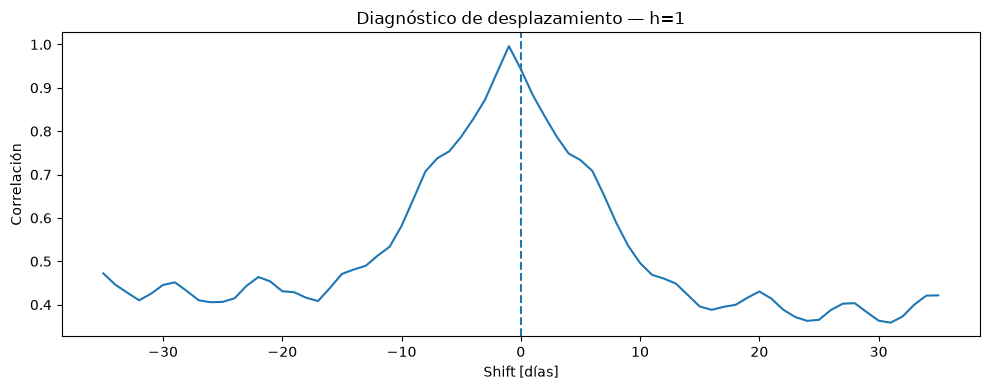

h=7: mejor shift=-7 días | corr máx=0.971 | corr en 0=0.735


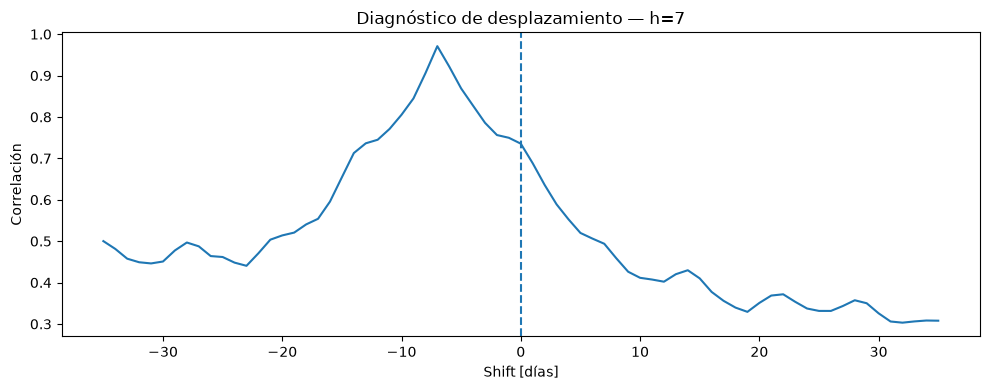

h=30: mejor shift=-30 días | corr máx=0.860 | corr en 0=0.425


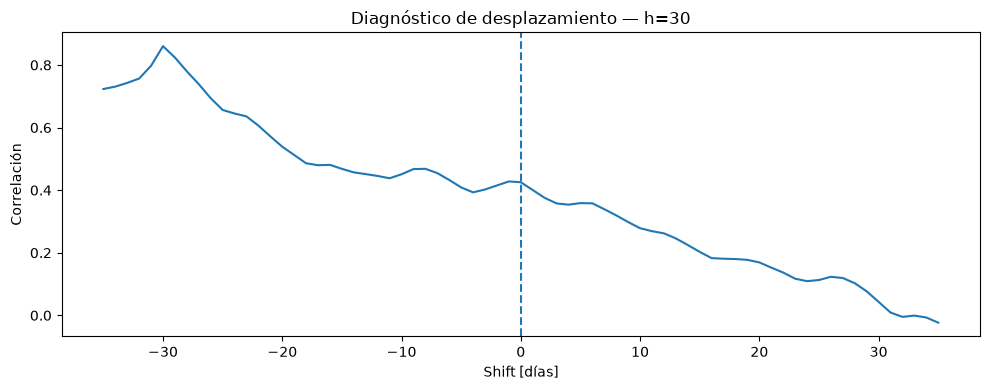

In [12]:
# Diagnóstico del "rezago": busca qué desplazamiento maximiza la correlación.
diag=[]
for h in HORIZONTES:
    z=pred_test[h][["real","pred"]].dropna()
    for shift in range(-35,36):
        diag.append({"Horizonte":h,"Shift_dias":shift,
                     "Correlacion":z["real"].corr(z["pred"].shift(shift))})
diag=pd.DataFrame(diag)

for h in HORIZONTES:
    d=diag[diag.Horizonte==h].dropna()
    k=d.loc[d.Correlacion.idxmax()]
    c0=d.loc[d.Shift_dias==0,"Correlacion"].iloc[0]
    print(f"h={h}: mejor shift={int(k.Shift_dias):+d} días | corr máx={k.Correlacion:.3f} | corr en 0={c0:.3f}")
    plt.figure(figsize=(10,4)); plt.plot(d.Shift_dias,d.Correlacion); plt.axvline(0,linestyle="--")
    plt.title(f"Diagnóstico de desplazamiento — h={h}"); plt.xlabel("Shift [días]"); plt.ylabel("Correlación")
    plt.tight_layout(); plt.show()

In [13]:
# Guardado en la estructura común del proyecto.
if METRICS.exists():
    old=pd.read_parquet(METRICS)
    if {"Modelo","Horizonte"}.issubset(old.columns):
        old=old[~(old["Modelo"].eq("GRU_Bayes_Ana_Corregida") & old["Horizonte"].isin(HORIZONTES))]
    table=pd.concat([old,test_metrics],ignore_index=True)
else:
    table=test_metrics.copy()
table.to_parquet(METRICS,index=False)

for h,z in pred_test.items(): z.to_csv(REPORT_DIR/f"predicciones_test_h{h}.csv")

torch.save({"state_dict":model.state_dict(),"config":best_cfg,
            "features":FEATURES,"horizontes":HORIZONTES},
           MODEL_DIR/"GRU_Bayes_Ana_Corregida.pt")

print("Métricas:",METRICS)
print("Modelo:",MODEL_DIR/"GRU_Bayes_Ana_Corregida.pt")
print("Reportes:",REPORT_DIR)

Métricas: /Users/maguverm/Documents/tesis-bolsa/data/processed/tabla_metricas.parquet
Modelo: /Users/maguverm/Documents/tesis-bolsa/models/gru_bayesiana_ana_corregida/GRU_Bayes_Ana_Corregida.pt
Reportes: /Users/maguverm/Documents/tesis-bolsa/reports/gru_bayesiana_ana_corregida


## Lectura del diagnóstico

Si el problema observado por Ana provenía principalmente de la asignación incorrecta de fechas, los gráficos de esta versión ya no deben aparecer corridos por construcción.

El bloque de diagnóstico de desplazamiento sirve como comprobación adicional: si la máxima correlación queda cerca de `Shift_dias = 0`, no hay evidencia de un simple rezago gráfico. Si el máximo aparece sistemáticamente lejos de cero, entonces existe un comportamiento dinámico del modelo que merece analizarse aparte.

**Todavía no se incorpora la modificación adicional solicitada por el profesor.** Conviene ejecutar y validar primero esta versión corregida.